In [1]:
import pandas as pd
import json

PATH_RAW = '../data/raw/'

account= pd.read_csv(f'{PATH_RAW}ravenstack_accounts.csv')
churn_events= pd.read_csv(f'{PATH_RAW}ravenstack_churn_events.csv')
feature_usage= pd.read_csv(f'{PATH_RAW}ravenstack_feature_usage.csv')
subscriptions= pd.read_csv(f'{PATH_RAW}ravenstack_subscriptions.csv')
support_tickets= pd.read_csv(f'{PATH_RAW}ravenstack_support_tickets.csv')




In [2]:
##Her tablo için kontroller
account.shape
account.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   account_id       500 non-null    object
 1   account_name     500 non-null    object
 2   industry         500 non-null    object
 3   country          500 non-null    object
 4   signup_date      500 non-null    object
 5   referral_source  500 non-null    object
 6   plan_tier        500 non-null    object
 7   seats            500 non-null    int64 
 8   is_trial         500 non-null    bool  
 9   churn_flag       500 non-null    bool  
dtypes: bool(2), int64(1), object(7)
memory usage: 32.4+ KB


In [3]:
account.head()
account.isna().mean()

account_id         0.0
account_name       0.0
industry           0.0
country            0.0
signup_date        0.0
referral_source    0.0
plan_tier          0.0
seats              0.0
is_trial           0.0
churn_flag         0.0
dtype: float64

In [4]:
print("\n--- Veri Boyutları ---")
print(f"Account shape: {account.shape}")
print(f"Churn shape: {churn_events.shape}")
print(f"Feature shape: {feature_usage.shape}")
print(f"subscriptions shape : {subscriptions.shape}")
print(f"support tickets shape : {support_tickets.shape}")

print("\n--- Account sütunları ---")
print(account.columns.tolist())

print("\n--- Churn sütunları ---")
print(churn_events.columns.tolist())

print("\n--- Feature sütunları ---")
print(feature_usage.columns.tolist())

print("\n--- subscriptions sütunları ---")
print(subscriptions.columns.tolist())

print("\n--- support tickets ---")
print(support_tickets.columns.tolist())

print("\n--- Account infos ---")
print(account.info())

print("\n--- Churn infos ---")
print(churn_events.info())

print("\n--- Feature infos ---")
print(feature_usage.info())

print("\n--- subscriptions infos ---")
print(subscriptions.info())

print("\n--- support tickets infos ---")
print(support_tickets.info())



--- Veri Boyutları ---
Account shape: (500, 10)
Churn shape: (600, 9)
Feature shape: (25000, 8)
subscriptions shape : (5000, 14)
support tickets shape : (2000, 9)

--- Account sütunları ---
['account_id', 'account_name', 'industry', 'country', 'signup_date', 'referral_source', 'plan_tier', 'seats', 'is_trial', 'churn_flag']

--- Churn sütunları ---
['churn_event_id', 'account_id', 'churn_date', 'reason_code', 'refund_amount_usd', 'preceding_upgrade_flag', 'preceding_downgrade_flag', 'is_reactivation', 'feedback_text']

--- Feature sütunları ---
['usage_id', 'subscription_id', 'usage_date', 'feature_name', 'usage_count', 'usage_duration_secs', 'error_count', 'is_beta_feature']

--- subscriptions sütunları ---
['subscription_id', 'account_id', 'start_date', 'end_date', 'plan_tier', 'seats', 'mrr_amount', 'arr_amount', 'is_trial', 'upgrade_flag', 'downgrade_flag', 'churn_flag', 'billing_frequency', 'auto_renew_flag']

--- support tickets ---
['ticket_id', 'account_id', 'submitted_at', 'c

In [5]:
#date sütunlarını str den DATE type a dönüştürelim, min & max'ı kontrol edelim

account['signup_date'] = pd.to_datetime(account['signup_date'], errors='coerce')
churn_events['churn_date'] = pd.to_datetime(churn_events['churn_date'], errors='coerce')
feature_usage['usage_date'] = pd.to_datetime(feature_usage['usage_date'], errors='coerce')
subscriptions['start_date'] = pd.to_datetime(subscriptions['start_date'], errors='coerce')
subscriptions['end_date'] = pd.to_datetime(subscriptions['end_date'], errors='coerce')
support_tickets['submitted_at'] = pd.to_datetime(support_tickets['submitted_at'], errors='coerce')
support_tickets['closed_at'] = pd.to_datetime(support_tickets['closed_at'], errors='coerce')

In [6]:
tables = {
    'accounts': account,
    'subscriptions': subscriptions,
    'feature_usage': feature_usage,
    'support_tickets': support_tickets,
    'churn_events': churn_events,
}

date_summary = pd.concat({
    name: df.select_dtypes(include='datetime').agg(['min', 'max', 'count']).T
    for name, df in tables.items()
})
date_summary

min                  max  count
accounts        signup_date   2023-01-02 00:00:00  2024-12-31 00:00:00    500
subscriptions   start_date    2023-01-09 00:00:00  2024-12-31 00:00:00   5000
                end_date      2023-04-05 00:00:00  2024-12-31 00:00:00    486
feature_usage   usage_date    2023-01-01 00:00:00  2024-12-31 00:00:00  25000
support_tickets submitted_at  2023-01-02 00:00:00  2024-12-31 00:00:00   2000
                closed_at     2023-01-03 03:00:00  2024-12-31 19:00:00   2000
churn_events    churn_date    2023-01-25 00:00:00  2024-12-31 00:00:00    600

In [7]:
#submitted_at değerlerinin hepsi gece yarısı (00:00) ama closed_at saat bilgisi de taşıyor (03:00, 19:00 gibi). Yani ticket’ın açılış saati muhtemelen kaydedilmemiş,

In [8]:
#closed_at < submitted_at olan, yani açılmadan kapanmış görünen ticket var mı?
(support_tickets['closed_at'] < support_tickets['submitted_at']).sum()

np.int64(0)

In [9]:
#Grain kontrolü
id_cols = {
    'accounts': 'account_id',
    'subscriptions': 'subscription_id',
    'feature_usage': 'usage_id',
    'support_tickets': 'ticket_id',
    'churn_events': 'churn_event_id',
}

for name, col in id_cols.items():
    df = tables[name]
    print(f"{name:16} rows={len(df):6}  unique {col}={df[col].nunique():6}  is_unique={df[col].is_unique}")

print()
for cols in [['subscription_id', 'usage_date'],
             ['subscription_id', 'usage_date', 'feature_name']]:
    print(f"feature_usage duplicates on {cols}: {feature_usage.duplicated(subset=cols).sum()}")

accounts         rows=   500  unique account_id=   500  is_unique=True
subscriptions    rows=  5000  unique subscription_id=  5000  is_unique=True
feature_usage    rows= 25000  unique usage_id= 24979  is_unique=False
support_tickets  rows=  2000  unique ticket_id=  2000  is_unique=True
churn_events     rows=   600  unique churn_event_id=   600  is_unique=True

feature_usage duplicates on ['subscription_id', 'usage_date']: 78
feature_usage duplicates on ['subscription_id', 'usage_date', 'feature_name']: 3


In [10]:
#Tekrar eden 21 ID var, Eğer satırların tamamı birbirlerinin kopyasıysa bu tekrar eden ID leri sileriz.
feature_usage.duplicated().sum()
#Gösterilecek satır yok, ancak görmek istersem:
feature_usage[feature_usage.duplicated(keep=False)].sort_values('usage_id')

,usage_id,subscription_id,usage_date,feature_name,usage_count,usage_duration_secs,error_count,is_beta_feature


In [11]:
#Sonuç 0, yani tam kopya yok. 21 ID tekrar ediyor ama bu ID’leri taşıyan satırların içeriği farklı. Silinecek bir şey yok.
#Aynı ID'leri taşıyan satırları görelim:
feature_usage[feature_usage.duplicated(subset='usage_id', keep=False)].sort_values('usage_id')


,usage_id,subscription_id,usage_date,feature_name,usage_count,usage_duration_secs,error_count,is_beta_feature
19294,U-0c9318,S-01b2dc,2023-12-11,feature_9,5,1060,3,False
17533,U-0c9318,S-0ffab0,2024-01-30,feature_11,3,1614,0,False
20588,U-13ce5b,S-9b623b,2023-03-26,feature_28,10,2050,1,False
9626,U-13ce5b,S-8b0950,2024-09-10,feature_9,8,824,0,True
18480,U-2103bb,S-7fc49b,2023-04-18,feature_12,9,5022,1,False
10379,U-2103bb,S-ae3270,2024-01-06,feature_3,10,5510,0,False
22,U-25b56c,S-810c27,2024-10-06,feature_20,7,231,0,False
7574,U-25b56c,S-34253c,2023-10-28,feature_20,6,2166,1,False
21376,U-48a4aa,S-93f835,2024-08-24,feature_39,10,4770,0,False
1085,U-48a4aa,S-383ac2,2023-02-12,feature_28,14,7126,0,False


In [12]:
usage_sub = pd.merge(
    feature_usage,
    subscriptions[['subscription_id', 'account_id', 'start_date', 'end_date']],
    left_on='subscription_id',
    right_on='subscription_id',
    how='left')
len(usage_sub)
    

25000

In [13]:
(usage_sub['usage_date'] < usage_sub['start_date']).sum()

np.int64(19142)

In [14]:
(usage_sub['usage_date'] > usage_sub['end_date']).sum()

np.int64(290)

In [15]:
usage_sub['account_id'].isna().sum()

np.int64(0)

In [16]:
usage_sub = pd.merge(
    usage_sub,
    account[['account_id', 'signup_date']],
    on='account_id',
    how='left',
    validate='many_to_one'
)

print(len(usage_sub))
print((usage_sub['usage_date'] < usage_sub['signup_date']).sum())

25000
13198


In [17]:
signup = account[['account_id', 'signup_date']]

tickets_acc = pd.merge(support_tickets, signup, on='account_id', how='left', validate='many_to_one')
churn_acc = pd.merge(churn_events, signup, on='account_id', how='left', validate='many_to_one')

tickets_before = (tickets_acc['submitted_at'] < tickets_acc['signup_date']).sum()
churn_before = (churn_acc['churn_date'] < churn_acc['signup_date']).sum()

print(f"support_tickets: {len(tickets_acc)} rows, {tickets_before} before signup ({tickets_before / len(tickets_acc):.1%})")
print(f"churn_events:    {len(churn_acc)} rows, {churn_before} before signup ({churn_before / len(churn_acc):.1%})")

support_tickets: 2000 rows, 1077 before signup (53.8%)
churn_events:    600 rows, 0 before signup (0.0%)


### feature_usage'da tarih tutarlılığı üzerine notlar

feature_usage'ı subscriptions ile birleştirirken kullanım tarihlerinin gerçekten abonelik dönemi içine düşüp düşmediğine baktım. Çoğu düşmüyor:

- 19.142 satırda (~%77) usage_date, aboneliğin start_date'inden **önce**
- 290 satırda usage_date, aboneliğin end_date'inden **sonra**

Sonra kullanım tarihlerini hesabın kayıt tarihiyle karşılaştırdım: 13.198 satır (~%53), hesap daha kaydolmadan önceki bir tarihte görünüyor.

Bence bu tablodaki tarihler diğer tablolardan bağımsız olarak üretilmiş, o yüzden bir kullanım satırını belirli bir abonelik dönemine bağlamak güvenilir değil. subscription_id'yi sadece her kullanım satırını account_id'ye eşlemek için kullanacağım ve kullanımı hesap düzeyinde ele alacağım.

Kayıttan önceki kullanım mantıken mümkün değil, bu yüzden feature'ları oluşturmadan önce bu satırları çıkarıyorum. Tablo kabaca yarıya iniyor ama bunları tutmak toplam kullanım ya da son aktiviteden bu yana geçen gün gibi feature'lara sadece gürültü ekler. Bu, kalan satırları otomatik olarak güvenilir yapmıyor; ama en azından feature'lar hesap var olmadan önceki olayları saymamış olacak.

ticket’ların da yaklaşık %54'ü kayıttan önce, aynı kuralı onlara da uyguluyorum; churn event’lerinin ise hiçbiri kayıttan önce değil, yani hedef değişken hesaplarla tutarlı

In [19]:
#Eşleşmeyen hesaplar
print("usage rows without account_id:   ", usage_sub['account_id'].isna().sum())
print("usage rows without signup_date:  ", usage_sub['signup_date'].isna().sum())
print("tickets without matching account:", tickets_acc['signup_date'].isna().sum())
print("churn events without account:    ", churn_acc['signup_date'].isna().sum())

usage rows without account_id:    0
usage rows without signup_date:   0
tickets without matching account: 0
churn events without account:     0


In [20]:
#Hesap Kaydından Önce Başlayan Abonelikler
subs_acc = pd.merge(subscriptions, signup, on='account_id', how='left', validate='many_to_one')
subs_before = (subs_acc['start_date'] < subs_acc['signup_date']).sum()

print(f"subscriptions: {len(subs_acc)} rows, {subs_before} start before signup ({subs_before / len(subs_acc):.1%})")

subscriptions: 5000 rows, 0 start before signup (0.0%)


In [21]:
#Churn Tutarlılığı

# Kaç hesap kaç kez churn etmiş?
churn_counts = churn_events['account_id'].value_counts()
print("Churn events per account (number of churns -> number of accounts):")
print(churn_counts.value_counts().sort_index())
print()

# churn_flag ile churn_events karşılaştırması
flagged = set(account.loc[account['churn_flag'], 'account_id'])
in_events = set(churn_events['account_id'])

print("accounts with churn_flag=True:         ", len(flagged))
print("unique accounts in churn_events:       ", len(in_events))
print("flagged AND in events:                 ", len(flagged & in_events))
print("flagged but NO churn event:            ", len(flagged - in_events))
print("has churn event but flag=False:        ", len(in_events - flagged))
print()

# Reactivation bayrağı
print(churn_events['is_reactivation'].value_counts())

Churn events per account (number of churns -> number of accounts):
count
1    177
2    116
3     47
4     10
5      2
Name: count, dtype: int64

accounts with churn_flag=True:          110
unique accounts in churn_events:        352
flagged AND in events:                  75
flagged but NO churn event:             35
has churn event but flag=False:         277

is_reactivation
False    539
True      61
Name: count, dtype: int64


### Hedef değişken: churn_flag mi, churn_events mi?

Hedefi tanımlamadan önce accounts'taki churn_flag ile churn_events tablosunun aynı hesapları gösterip göstermediğine baktım. İkisi birbirini pek tutmuyor:

- 500 hesabın 352'sinin (~%70) en az bir churn event'i var, bunların 175'i birden fazla kez churn etmiş (en fazla 5 kez)
- churn_flag=True olan 110 hesap var, ama bunların 35'inin hiç churn event'i yok
- Churn event'i olan 352 hesabın 277'si churn_flag=False

İlk aklıma gelen, churn_flag'in hesabın bugünkü durumunu gösterdiği ve churn edip geri dönenlerin False olduğuydu. Ama is_reactivation=True olan sadece 61 event var, bu 277 hesaplık farkı açıklamıyor. Yani iki kaynak aynı şeyi ölçmüyor ya da birbirinden bağımsız üretilmiş. Hangisinin "doğru" olduğunu veriden kesin olarak söyleyemiyorum.

Hedefi churn_events'teki tarihlerden tanımlamaya karar verdim: "T tarihinden sonraki N gün içinde churn event'i var mı?" Sebebi şu:
- churn_date'lerin hiçbiri hesabın kayıt tarihinden önce değil, yani tarihler hesaplarla tutarlı (kullanım ve ticket'larda bu oran ~%53'tü)
- Tarih olduğu için zaman pencereli bir soru sorabiliyorum ve hangi bilginin churn'den önce olduğunu kontrol edebiliyorum. churn_flag'de bu mümkün değil
- Aynı hesabın birden fazla churn'ü snapshot yapısıyla doğal olarak ele alınıyor

churn_flag'i (hem accounts hem subscriptions'taki) modelde hiç kullanmıyorum, hedefi doğrudan ele veriyor. Bir de churn event'i "hesabın tamamen ayrılması" olarak değil, "bir churn olayı" olarak yorumluyorum. Veri seti açıklaması ikisi arasındaki farkı netleştirmiyor.

         churn_events  signups
2023-01           1.0       17
2023-02           0.0       18
2023-03           5.0       20
2023-04           3.0       15
2023-05           3.0       26
2023-06           5.0       13
2023-07           6.0       14
2023-08           7.0       16
2023-09           6.0       23
2023-10          10.0       20
2023-11          11.0       25
2023-12          16.0       20
2024-01          20.0       16
2024-02          10.0       13
2024-03          24.0       27
2024-04          25.0       22
2024-05          27.0       22
2024-06          40.0       21
2024-07          35.0       26
2024-08          42.0       21
2024-09          53.0       25
2024-10          66.0       31
2024-11          68.0       32
2024-12         117.0       17


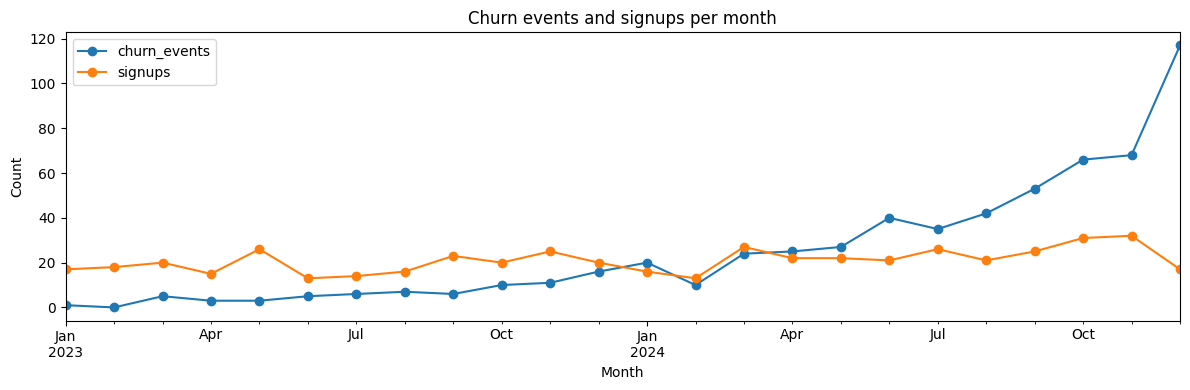

In [22]:
#Churn'ın zamana dağılımı
import matplotlib.pyplot as plt

churn_monthly = churn_events['churn_date'].dt.to_period('M').value_counts().sort_index()
signup_monthly = account['signup_date'].dt.to_period('M').value_counts().sort_index()

monthly = pd.DataFrame({'churn_events': churn_monthly, 'signups': signup_monthly}).fillna(0)
print(monthly)

ax = monthly.plot(marker='o', figsize=(12, 4), title='Churn events and signups per month')
ax.set_xlabel('Month')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

         churn_events  cumulative_accounts  churn_rate
2023-01           1.0                   17       0.059
2023-02           0.0                   35       0.000
2023-03           5.0                   55       0.091
2023-04           3.0                   70       0.043
2023-05           3.0                   96       0.031
2023-06           5.0                  109       0.046
2023-07           6.0                  123       0.049
2023-08           7.0                  139       0.050
2023-09           6.0                  162       0.037
2023-10          10.0                  182       0.055
2023-11          11.0                  207       0.053
2023-12          16.0                  227       0.070
2024-01          20.0                  243       0.082
2024-02          10.0                  256       0.039
2024-03          24.0                  283       0.085
2024-04          25.0                  305       0.082
2024-05          27.0                  327       0.083
2024-06   

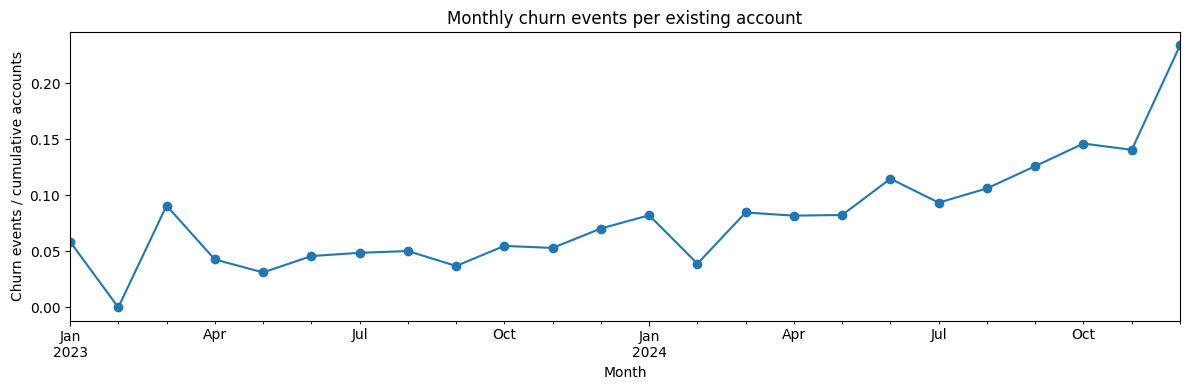

In [23]:
monthly['cumulative_accounts'] = monthly['signups'].cumsum()
monthly['churn_rate'] = monthly['churn_events'] / monthly['cumulative_accounts']

print(monthly[['churn_events', 'cumulative_accounts', 'churn_rate']].round(3))

ax = monthly['churn_rate'].plot(marker='o', figsize=(12, 4), title='Monthly churn events per existing account')
ax.set_xlabel('Month')
ax.set_ylabel('Churn events / cumulative accounts')
plt.tight_layout()
plt.show()

**Churn'ün zamana dağılımı**
- Churn'lerin ~%90'ı 2024'te. Hesap başına aylık churn oranı 2023'te ~%4-5, 2024 sonunda ~%14, Aralık 2024'te %23
- Artış sadece hesap birikiminden değil, oran da gerçekten yükseliyor. Bu yüzden zamana göre split'te train ve test arasında belirgin bir dağılım kayması olacak
- Aralık 2024'teki sıçrama gerçek bir sezonluk etki mi yoksa veri üretim artefaktı mı, ayırt edemiyorum